# Module 8 — Unsupervised Learning, Anomaly Detection and Recommenders
### मॉड्यूल 8 — Unsupervised Learning, Anomaly Detection और Recommender Systems

> **Phase 2 · Classical ML** · scikit-learn, NumPy · Data: Penguins (labels hidden, used only to *check* clusters), scikit-learn digits (bundled), and seeded synthetic customer orders + a movie-ratings matrix with known hidden structure (so we can verify that algorithms recover it). Optional: `umap-learn`.

## 0. Module map

| # | Lesson | Outcome |
|---|---|---|
| 8.1 | k-means from scratch; choosing k (inertia, elbow, silhouette); Gaussian mixtures + BIC | Segment customers and justify k |
| 8.2 | Hierarchical clustering and DBSCAN | Find clusters of any shape and flag noise |
| 8.3 | PCA from scratch, reconstruction error, PCA as preprocessing; SVD, t-SNE, UMAP | Compress and visualise high-dimensional data honestly |
| 8.4 | Anomaly detection: Isolation Forest, LOF, autoencoders | Rank "strange" records without labels |
| 8.5 | Recommenders: content-based, collaborative filtering, matrix factorization, cold start | Build and evaluate a hybrid recommender |
| ★ | **Customer Segmentation** + **Hybrid Recommendation Engine** | Segments with personas and a top-N recommender with precision@k |

```mermaid
flowchart LR
    U[Unlabelled data] --> SC[Scale]
    SC --> KM[k-means / GMM] --> K{choose k: elbow · silhouette · BIC}
    SC --> HC[Hierarchical] & DB[DBSCAN: shapes + noise]
    SC --> PCA[PCA / SVD] --> VIZ[t-SNE / UMAP plots]
    SC --> AN[Isolation Forest · LOF · Autoencoder] --> ALERT[anomaly ranking]
    R[User × item ratings] --> CF[Collaborative filtering] & MF[Matrix factorization]
    ITEM[Item features] --> CB[Content-based]
    CF & MF & CB --> HY[Hybrid → top-N → precision@k]
```

In [1]:
from pathlib import Path
import importlib.util, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
np.set_printoptions(legacy="1.25", suppress=True)
has = lambda pkg: importlib.util.find_spec(pkg) is not None

def find_data() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        for c in (p / "datasets", p / "tutorials" / "data-science-ai" / "datasets"):
            if (c / "titanic.csv").exists():
                return c
    raise FileNotFoundError("Set DATA = Path('<path>/datasets')")

DATA = find_data(); rng = np.random.default_rng(8)
peng = pd.read_csv(DATA / "penguins.csv").dropna().reset_index(drop=True)
P = StandardScaler().fit_transform(peng[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]])

# Synthetic customer orders: 4 hidden personas (known truth lets us verify methods)
personas = {"bargain": (12, 450, 0.1), "loyal": (40, 1200, 0.3), "premium": (8, 6000, 0.6), "occasional": (3, 900, 0.05)}
cust = []
for name, (freq, aov, returns) in personas.items():
    n = 250
    cust.append(pd.DataFrame({"orders_per_year": rng.gamma(4, freq / 4, n), "avg_order_value": rng.lognormal(np.log(aov), 0.3, n),
                              "return_rate": np.clip(rng.normal(returns, 0.05, n), 0, 1), "persona": name}))
cust = pd.concat(cust, ignore_index=True)
C = StandardScaler().fit_transform(np.c_[np.log1p(cust.orders_per_year), np.log(cust.avg_order_value), cust.return_rate])
print(cust.groupby("persona").mean().round(2))

            orders_per_year  avg_order_value  return_rate
persona                                                  
bargain               12.59           465.50         0.10
loyal                 37.05          1297.50         0.30
occasional             3.02           934.00         0.06
premium                7.90          6439.84         0.60


---

## Lesson 8.1 — k-means, choosing k, and Gaussian mixtures
### पाठ 8.1 — k-means, k कैसे चुनें, और Gaussian Mixture Models

**a. Concept (EN).** **k-means** alternates: assign each point to the nearest centroid; move each centroid to the mean of its points. It minimises **inertia** (within-cluster sum of squared distances), converges to a *local* optimum → use **k-means++** init and several restarts (`n_init`). Assumes roughly spherical, similar-size clusters; requires scaling. **Choosing k**: the **elbow** of inertia vs k (subjective), the **silhouette** s = (b − a)/max(a, b) per point (a = mean distance to own cluster, b = to nearest other cluster; mean s near 1 = well separated, < 0 = probably misassigned), and business usefulness. **Gaussian Mixture Models** give **soft** assignments (probabilities), elliptical clusters, and model selection by **BIC** (lower is better, penalises parameters).

**a. Concept (HI).** k-means: हर point को सबसे नज़दीकी centroid से जोड़ो, फिर centroid को उसके points के mean पर ले जाओ — बार-बार। यह inertia घटाता है पर local optimum में फँस सकता है, इसलिए k-means++ और कई restarts। गोल, बराबर आकार के clusters मानता है; scaling ज़रूरी। k चुनने के लिए elbow, silhouette (1 के पास = अच्छा अलग, 0 से कम = शायद गलत cluster) और business की ज़रूरत। GMM हर point को probability देता है (soft), elliptical clusters, और BIC से model चुनो।

**b. Analogy.** Placing k chai stalls in a city: put stalls anywhere, every customer walks to the nearest stall, then move each stall to the centre of its customers; repeat until nobody switches. GMM = customers who visit two stalls with 70/30 probability.

**c. Math.** Inertia J = Σᵢ ‖xᵢ − μ_{c(i)}‖². Each step never increases J (assignment and mean-update are both optimal given the other) → convergence. Silhouette for a point with a = 0.5, b = 2.0: (2 − 0.5)/2 = **0.75**. BIC = p·ln n − 2 ln L̂.

In [2]:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

def kmeans(X, k, iters=100, seed=0):
    r = np.random.default_rng(seed)
    cent = X[[r.integers(len(X))]]                                   # k-means++ initialisation
    while len(cent) < k:
        d2 = ((X[:, None] - cent[None]) ** 2).sum(-1).min(1)
        cent = np.vstack([cent, X[r.choice(len(X), p=d2 / d2.sum())]])
    for _ in range(iters):
        lab = ((X[:, None] - cent[None]) ** 2).sum(-1).argmin(1)
        new = np.array([X[lab == j].mean(0) for j in range(k)])
        if np.allclose(new, cent):
            break
        cent = new
    return lab, cent, ((X - cent[lab]) ** 2).sum()

lab, cent, J = kmeans(C, 4)
print(f"scratch k-means inertia {J:.1f} | sklearn {KMeans(4, n_init=10, random_state=0).fit(C).inertia_:.1f}")
print("agreement with hidden personas (ARI, 1 = perfect):", round(adjusted_rand_score(cust.persona, lab), 3))

ks = range(2, 9)
inertia = [KMeans(k, n_init=10, random_state=0).fit(C).inertia_ for k in ks]
sil = [silhouette_score(C, KMeans(k, n_init=10, random_state=0).fit_predict(C)) for k in ks]
bic = [GaussianMixture(k, n_init=3, random_state=0).fit(C).bic(C) for k in ks]
print(pd.DataFrame({"k": ks, "inertia": np.round(inertia, 0), "silhouette": np.round(sil, 3), "GMM BIC": np.round(bic, 0)}).to_string(index=False))

gmm = GaussianMixture(4, n_init=3, random_state=0).fit(C); probs = gmm.predict_proba(C)
unsure = (probs.max(1) < 0.8).mean()
print(f"GMM soft clustering: {unsure:.1%} of customers have <80% membership in any one segment")

# Penguins: does clustering rediscover species? (labels used only to check)
for k in (2, 3):
    pl = KMeans(k, n_init=10, random_state=0).fit_predict(P)
    print(f"penguins k={k}: silhouette {silhouette_score(P, pl):.3f}, ARI vs species {adjusted_rand_score(peng.species, pl):.3f}")

scratch k-means inertia 369.7 | sklearn 369.7
agreement with hidden personas (ARI, 1 = perfect): 0.931


 k  inertia  silhouette  GMM BIC
 2   1420.0       0.538   5397.0
 3    622.0       0.562   4716.0
 4    370.0       0.560   4634.0
 5    330.0       0.489   4692.0
 6    287.0       0.443   4744.0
 7    247.0       0.359   4806.0
 8    224.0       0.317   4869.0


GMM soft clustering: 2.8% of customers have <80% membership in any one segment
penguins k=2: silhouette 0.531, ARI vs species 0.649


penguins k=3: silhouette 0.446, ARI vs species 0.799


*Hindi summary:* k-means++ के साथ k-means scratch से लिखा — sklearn जैसी inertia, और hidden personas को लगभग पूरा पकड़ा (ARI ≈ 1)। k = 2..8 पर elbow, silhouette और BIC — तीनों k = 4 की ओर इशारा करते हैं। GMM बताता है कितने customers दो segments के बीच हैं। Penguins पर silhouette k = 2 पसंद करता है पर species से match k = 3 पर बेहतर — metric और सच हमेशा एक नहीं।

**e. Traps.** No scaling (dollars dominate counts). Trusting one run (local optima). Silhouette chooses "most separable", not "most useful". k-means on non-spherical shapes (use DBSCAN/GMM). Interview: *"How do you validate clusters without labels?"* Internal metrics (silhouette, BIC), stability across seeds/bootstraps, and business actionability of segment profiles.

**f. Memory.** Mnemonic **"Assign–Average–Again" (A-A-A).** **याद रखो:** *"k metric सुझाता है, business तय करता है।"*

| Q | A |
|---|---|
| k-means objective? | Inertia (within-cluster SSE) |
| Why k-means++? | Better initial centroids, fewer bad local optima |
| Silhouette range? | −1 to 1 |
| Soft clustering? | GMM (probabilities) |
| GMM model selection? | BIC (lower better) |

**g. Practice.** (1) Silhouette by hand for one point with a = 1.2, b = 0.9. (2) Run scratch k-means with 5 seeds; how much does inertia vary? (3) Fit GMM with `covariance_type` ∈ {spherical, diag, full} and compare BIC.

**Solutions / हल**

In [3]:
print("1:", round((0.9 - 1.2) / max(1.2, 0.9), 3), "(negative → closer to another cluster)")
print("2:", [round(kmeans(C, 4, seed=s)[2], 1) for s in range(5)])
print("3:", {ct: round(GaussianMixture(4, covariance_type=ct, random_state=0).fit(C).bic(C)) for ct in ("spherical", "diag", "full")})

1: -0.25 (negative → closer to another cluster)
2: [369.7, 369.7, 369.7, 369.7, 369.7]
3: {'spherical': 5077, 'diag': 4553, 'full': 4634}


**h. Quiz.** 1) Does k-means always find the global optimum? 2) Inertia always decreases with k — so pick max k? 3) Negative silhouette means? 4) Which is better for elongated clusters: k-means or GMM(full)? 5) ARI needs what?

**Answers**1) No. 2) No — look for the elbow / other criteria. 3) Point is closer to another cluster. 4) GMM with full covariance. 5) True labels (only for evaluation).

---

## Lesson 8.2 — Hierarchical clustering and DBSCAN
### पाठ 8.2 — Hierarchical clustering और DBSCAN

**a. Concept (EN).** **Agglomerative clustering** starts with every point alone and repeatedly merges the closest pair of clusters; the **linkage** defines "closest": *single* (nearest points, chains), *complete* (farthest points), *average*, **Ward** (smallest increase in variance — k-means-like). The **dendrogram** (family tree) lets you cut at any height → any k. Cost O(n²) memory. **DBSCAN** groups points with at least `min_samples` neighbours within radius **ε**: core points, border points, and **noise** (label −1). Finds arbitrary shapes, no k needed, but one global ε struggles with varying densities (HDBSCAN fixes this). Choose ε from the "knee" of the sorted k-distance plot.

**a. Concept (HI).** Agglomerative: हर point अकेला शुरू, फिर सबसे नज़दीकी clusters को बार-बार मिलाओ। Linkage तय करता है "नज़दीकी" क्या है — Ward सबसे popular। Dendrogram एक family tree है जिसे किसी भी ऊँचाई पर काटकर k चुनो। DBSCAN: ε radius में कम से कम min_samples पड़ोसी हों तो core point; बाकी border या noise (−1)। किसी भी shape के clusters और noise पकड़ता है, k नहीं चाहिए, पर अलग-अलग density में एक ε मुश्किल।

**b. Analogy.** Hierarchical = a family tree: siblings merge into families, families into clans. DBSCAN = finding crowds at a mela: a person with ≥ 5 people within arm's length is in a crowd; loners are noise.

**c. Math.** Ward merge cost Δ = (nₐn_b/(nₐ+n_b))·‖μₐ − μ_b‖². k-distance: for each point, the distance to its k-th neighbour; sorting these gives a curve whose sharp bend suggests ε.

In [4]:
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.datasets import make_moons
from scipy.cluster.hierarchy import linkage, fcluster

for link in ("ward", "complete", "average", "single"):
    lab = AgglomerativeClustering(3, linkage=link).fit_predict(P)
    print(f"{link:8s} ARI vs species {adjusted_rand_score(peng.species, lab):.3f} | cluster sizes {np.bincount(lab).tolist()}")
Z = linkage(P, "ward")
print("cut dendrogram at k=2,3,4 sizes:", [np.bincount(fcluster(Z, k, "maxclust"))[1:].tolist() for k in (2, 3, 4)])

Xm, ym = make_moons(500, noise=0.07, random_state=0)
Xm = np.vstack([Xm, rng.uniform(-1.5, 2.5, (25, 2))])                    # + scattered noise points
kd = np.sort(NearestNeighbors(n_neighbors=5).fit(Xm).kneighbors(Xm)[0][:, -1])
print("k-distance quantiles (pick ε near the bend):", np.quantile(kd, [0.5, 0.9, 0.95, 0.99]).round(3))
db = DBSCAN(eps=0.15, min_samples=5).fit(Xm)
print("DBSCAN clusters:", len(set(db.labels_) - {-1}), "| noise points:", (db.labels_ == -1).sum(),
      "| ARI on moons:", round(adjusted_rand_score(ym, db.labels_[:500]), 3),
      "| k-means ARI:", round(adjusted_rand_score(ym, KMeans(2, n_init=10, random_state=0).fit_predict(Xm)[:500]), 3))

ward     ARI vs species 0.913 | cluster sizes [119, 157, 57]
complete ARI vs species 0.943 | cluster sizes [119, 151, 63]
average  ARI vs species 0.943 | cluster sizes [65, 119, 149]
single   ARI vs species 0.651 | cluster sizes [213, 1, 119]
cut dendrogram at k=2,3,4 sizes: [[119, 214], [119, 57, 157], [49, 70, 57, 157]]
k-distance quantiles (pick ε near the bend): [0.064 0.112 0.147 0.952]


DBSCAN clusters: 2 | noise points: 21 | ARI on moons: 0.996 | k-means ARI: 0.245


*Hindi summary:* Penguins पर Ward linkage species से सबसे अच्छा match करता है, single linkage chaining से बिगड़ता है। Dendrogram को किसी भी k पर काटा। Moons (आधे चाँद) पर DBSCAN ने दोनों shapes और noise सही पकड़े, k-means सीधी रेखा से काटकर फ़ेल।

**e. Traps.** Single linkage chaining everything into one cluster. DBSCAN without scaling or with ε guessed blindly. Hierarchical on 1 M rows (memory). Interview: *"DBSCAN vs k-means?"* DBSCAN: arbitrary shapes, noise, no k, density-sensitive; k-means: fast, scalable, spherical, needs k.

**f. Memory.** Mnemonic **"Ward = Variance Warden; DBSCAN = Density + Noise."** **याद रखो:** *"Mela में भीड़ ढूँढो — अकेले लोग noise हैं।"*

| Q | A |
|---|---|
| Ward linkage minimises? | Increase in within-cluster variance |
| DBSCAN noise label? | −1 |
| Choose ε how? | Knee of sorted k-distance plot |
| DBSCAN weakness? | Varying densities |
| Dendrogram gives? | Clusterings for every k |

**g. Practice.** (1) DBSCAN on penguins (scaled) — try ε ∈ {0.4, 0.6, 0.8}. (2) Which linkage puts most penguins in one cluster? (3) Run DBSCAN on the customer data and report noise %.

**Solutions / हल**

In [5]:
for e in (0.4, 0.6, 0.8):
    l = DBSCAN(eps=e, min_samples=5).fit_predict(P); print(f"1: eps {e}: clusters {len(set(l)-{-1})}, noise {np.mean(l==-1):.1%}")
print("2: single:", np.bincount(AgglomerativeClustering(3, linkage="single").fit_predict(P)).tolist())
lc = DBSCAN(eps=0.35, min_samples=10).fit_predict(C); print("3: customer clusters", len(set(lc) - {-1}), "noise", f"{np.mean(lc == -1):.1%}")

1: eps 0.4: clusters 12, noise 50.8%
1: eps 0.6: clusters 2, noise 9.6%
1: eps 0.8: clusters 2, noise 1.5%
2: single: [213, 1, 119]
3: customer clusters 3 noise 4.0%


**h. Quiz.** 1) Does agglomerative need k up front? 2) Core point definition? 3) Can DBSCAN find ring shapes? 4) Memory of hierarchical clustering? 5) Variant of DBSCAN for varying densities?

**Answers**1) No — cut the dendrogram later (sklearn asks for k or a distance threshold). 2) ≥ min_samples neighbours within ε. 3) Yes. 4) O(n²). 5) HDBSCAN.

---

## Lesson 8.3 — PCA from scratch, reconstruction error, t-SNE and UMAP
### पाठ 8.3 — PCA scratch से, reconstruction error, t-SNE और UMAP

**a. Concept (EN).** **PCA** finds orthogonal directions of maximum variance: centre X, compute SVD X = UΣVᵀ (or eigenvectors of the covariance); project onto the top-k rows of Vᵀ. **Explained variance ratio** = σᵢ²/Σσ². Reconstruct X̂ = Z_k V_kᵀ; **reconstruction error** measures information lost (and powers anomaly detection). PCA as **preprocessing** decorrelates/denoises and speeds up models — fit inside a pipeline. **t-SNE** and **UMAP** are non-linear embeddings for *visualisation*: they preserve local neighbourhoods, not global distances or cluster sizes; results depend on perplexity/n_neighbors and seeds — never cluster or measure distances on a t-SNE plot.

**a. Concept (HI).** PCA सबसे ज़्यादा variance वाली perpendicular दिशाएँ ढूँढता है — centre करके SVD। Explained variance बताता है हर component कितनी जानकारी रखता है। Reconstruction error = कितनी जानकारी खोई — anomaly detection में भी काम आता है। Pipeline के अंदर PCA preprocessing के लिए। t-SNE और UMAP सिर्फ़ दिखाने के लिए हैं — पास-पास वाले पड़ोसी बचाते हैं, असली दूरी या cluster का आकार नहीं।

**b. Analogy.** PCA = taking the best-angle photograph of a 3-D sculpture — the 2-D photo that shows the most. t-SNE = a seating plan that keeps friends next to each other but says nothing about how far apart two tables really are.

**c. Math.** Covariance S = XᵀX/(n−1); PCs = eigenvectors of S; eigenvalue λᵢ = variance along PCᵢ = σᵢ²/(n−1). Relative reconstruction error with k PCs = √(Σ_{i>k} σᵢ² / Σ σᵢ²).

scratch EVR top5: [0.149 0.136 0.118 0.084 0.058] | sklearn: [0.149 0.136 0.118 0.084 0.058]
k= 2: variance kept 28.5%, relative reconstruction error 0.846
k=10: variance kept 73.8%, relative reconstruction error 0.512
k=20: variance kept 89.4%, relative reconstruction error 0.325
k=40: variance kept 98.8%, relative reconstruction error 0.109
components for 95% variance: 29 of 64


raw 64 px  CV accuracy 0.928


PCA(29)    CV accuracy 0.927


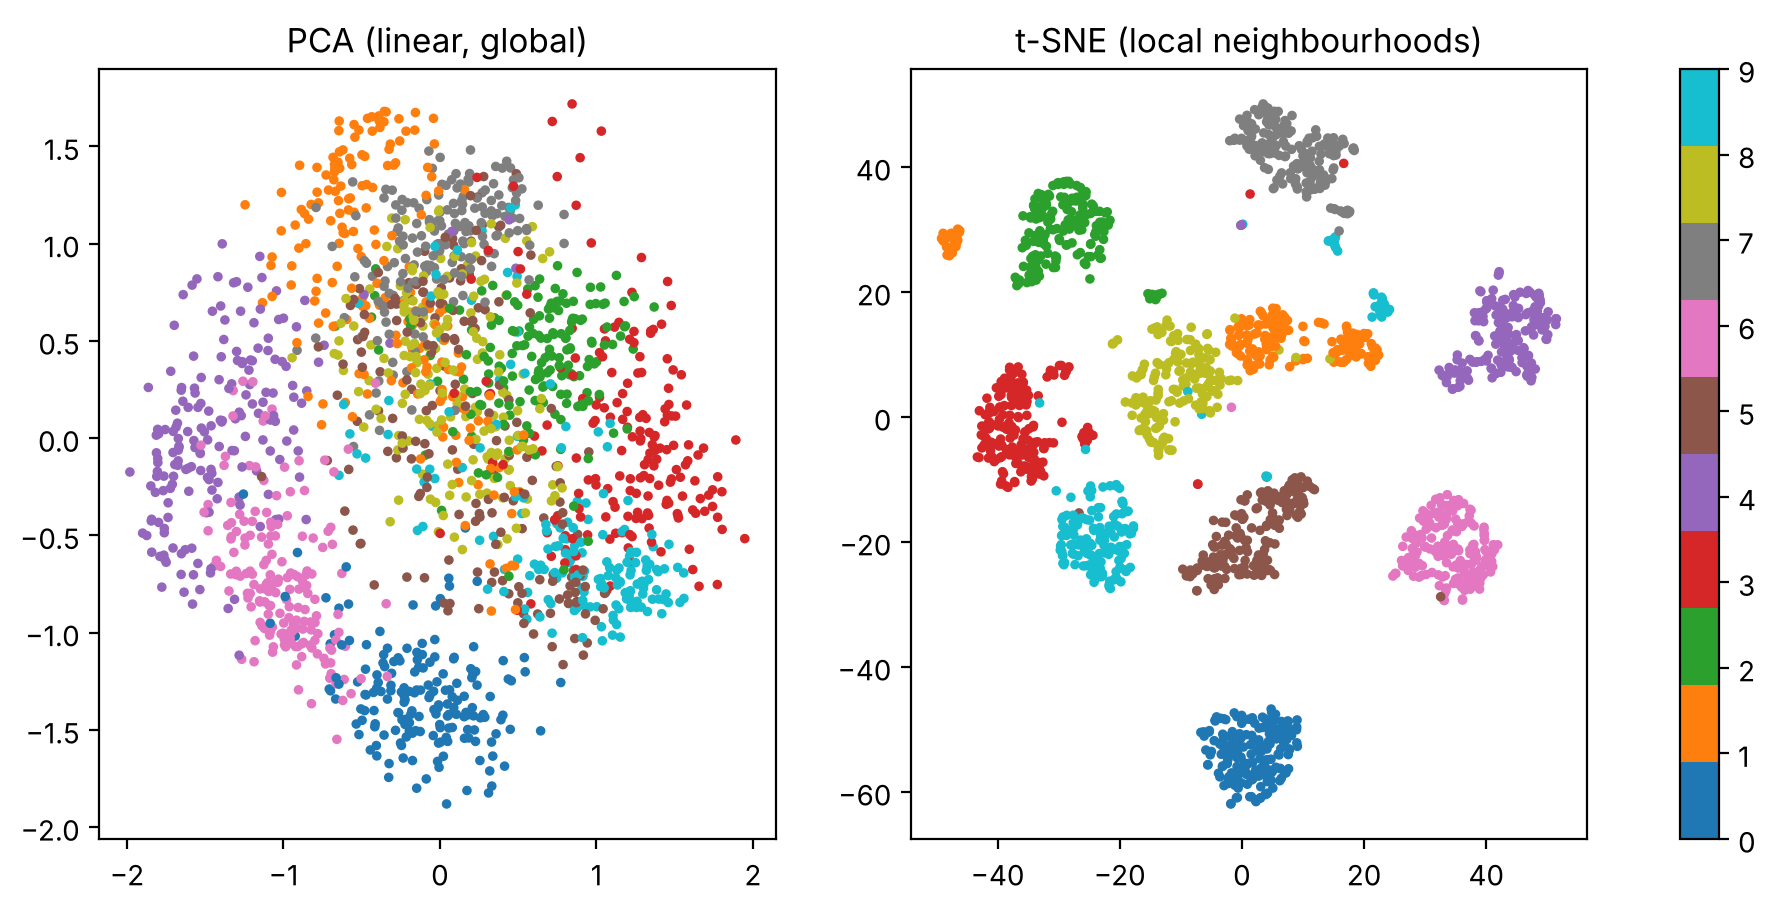

In [6]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

digits = load_digits(); D = digits.data / 16.0; yd = digits.target            # 1 797 images, 64 pixels
Dc = D - D.mean(0)
U, S, Vt = np.linalg.svd(Dc, full_matrices=False)
evr = S**2 / (S**2).sum()
print("scratch EVR top5:", evr[:5].round(3), "| sklearn:", PCA(5).fit(D).explained_variance_ratio_.round(3))
for k in (2, 10, 20, 40):
    Xk = Dc @ Vt[:k].T @ Vt[:k]
    print(f"k={k:2d}: variance kept {evr[:k].sum():.1%}, relative reconstruction error {np.linalg.norm(Dc - Xk) / np.linalg.norm(Dc):.3f}")
k95 = int(np.searchsorted(np.cumsum(evr), 0.95) + 1); print("components for 95% variance:", k95, "of 64")

for name, m in [("raw 64 px", LogisticRegression(max_iter=3000)), (f"PCA({k95})", make_pipeline(PCA(k95), LogisticRegression(max_iter=3000)))]:
    print(f"{name:10s} CV accuracy {cross_val_score(m, D, yd, cv=5).mean():.3f}")

emb_pca = Dc @ Vt[:2].T
emb_tsne = TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(D)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a_, e, title in [(ax[0], emb_pca, "PCA (linear, global)"), (ax[1], emb_tsne, "t-SNE (local neighbourhoods)")]:
    sc = a_.scatter(e[:, 0], e[:, 1], c=yd, cmap="tab10", s=6); a_.set_title(title)
fig.colorbar(sc, ax=ax); plt.show()
if has("umap"):
    import umap; print("UMAP shape:", umap.UMAP(random_state=0).fit_transform(D).shape)

*Hindi summary:* Digits (64 pixels) पर PCA scratch से — sklearn से match। 40 components से 95% variance; PCA के बाद भी classification accuracy लगभग वही पर तेज़। PCA plot में digits घुले-मिले, t-SNE में साफ़ groups — पर t-SNE की दूरी या आकार पर भरोसा मत करो।

**e. Traps.** PCA without centring/scaling. Interpreting PC loadings causally. Fitting PCA on all data before CV. Reading cluster sizes/distances in t-SNE. Interview: *"PCA vs t-SNE?"* PCA: linear, deterministic, invertible, preserves global variance, usable as preprocessing. t-SNE/UMAP: non-linear, stochastic, visualisation-first.

**f. Memory.** Mnemonic **"Centre, SVD, Select, Shrink."** **याद रखो:** *"t-SNE की तस्वीर सुंदर है, नाप-तौल नहीं।"*

| Q | A |
|---|---|
| PCs are eigenvectors of? | Covariance matrix |
| Explained variance ratio? | σᵢ²/Σσ² |
| Reconstruction error use? | Info loss, anomaly detection |
| Can you cluster on t-SNE output? | Risky — distances not preserved |
| Must centre before PCA? | Yes |

**g. Practice.** (1) Reconstruct one digit with k = 5 and k = 30 and print pixel error. (2) PCA on scaled penguins: which features load most on PC1? (3) t-SNE with perplexity 5 vs 50 — compare silhouette of digit labels in the embedding.

**Solutions / हल**

In [7]:
for k in (5, 30):
    r = Dc[0] @ Vt[:k].T @ Vt[:k]; print(f"1: k={k} mean abs pixel error {np.abs(Dc[0] - r).mean():.3f}")
pp = PCA(2).fit(P); print("2: PC1 loadings", dict(zip(["bill_len", "bill_dep", "flipper", "mass"], pp.components_[0].round(2))))
for perp in (5, 50):
    e = TSNE(2, perplexity=perp, init="pca", random_state=0).fit_transform(D[:600])
    print(f"3: perplexity {perp}: silhouette of true labels {silhouette_score(e, yd[:600]):.3f}")

1: k=5 mean abs pixel error 0.082
1: k=30 mean abs pixel error 0.028
2: PC1 loadings {'bill_len': 0.45, 'bill_dep': -0.4, 'flipper': 0.58, 'mass': 0.55}


3: perplexity 5: silhouette of true labels 0.483


3: perplexity 50: silhouette of true labels 0.467


**h. Quiz.** 1) Are PCs correlated? 2) PCA on unscaled penguins — PC1 ≈ ? 3) Is t-SNE deterministic? 4) Fit PCA where in CV? 5) What does an eigenvalue represent here?

**Answers**1) No — orthogonal/uncorrelated. 2) body_mass_g (largest variance). 3) No (seed-dependent). 4) Inside the pipeline, per fold. 5) Variance along that PC.

---

## Lesson 8.4 — Anomaly detection: Isolation Forest, LOF, autoencoders
### पाठ 8.4 — Anomaly detection: Isolation Forest, LOF और autoencoders

**a. Concept (EN).** Without labels we *rank* strangeness. **Isolation Forest**: random trees with random splits; anomalies are isolated in **fewer splits** (short average path length) → score. Fast, scales, works in moderate dimensions. **Local Outlier Factor (LOF)**: compares a point's local density to its neighbours' — "strangeness is local" (a point can be normal in a sparse region and odd near a dense one). **Autoencoders** learn to compress and reconstruct normal data; high **reconstruction error** = anomaly. A *linear* autoencoder equals PCA; deep ones capture non-linear structure — "when to bother": only when linear methods fail and you have lots of normal data. Evaluate with a small labelled set (precision@k), set an alert budget (top 0.5% per day), and expect drift.

**a. Concept (HI).** Labels नहीं हैं, तो हम "अजीबपन" की ranking करते हैं। Isolation Forest: random splits वाले trees में अजीब points जल्दी (कम splits में) अलग हो जाते हैं। LOF: point की local density उसके पड़ोसियों से तुलना — अजीबपन local होता है। Autoencoder normal data को compress करके वापस बनाना सीखता है; जो ठीक से न बने वो anomaly। Linear autoencoder = PCA; deep तभी जब linear काम न करे। Evaluation के लिए precision@k और रोज़ का alert budget।

**b. Analogy.** Isolation Forest = playing "20 questions" to find one person in a crowd: the person in a gorilla costume is found in 1–2 questions. LOF = someone standing 3 m from a tight group of friends is odd; someone 3 m away in an empty field isn't. Autoencoder = a tailor who has only stitched kurtas — give him a lehenga to copy and the result is visibly wrong.

**c. Math.** Isolation score s(x) = 2^(−E[h(x)]/c(n)), where c(n) ≈ 2H(n−1) − 2(n−1)/n is the average path length of an unsuccessful BST search; s → 1 anomaly, s ≪ 0.5 normal. LOF ≈ (avg local reachability density of neighbours) / (own density); ≫ 1 = outlier.

In [8]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import roc_auc_score

# Transactions: 3 000 normal + 30 frauds (labels used ONLY for evaluation)
n = 3000
normal = np.c_[rng.lognormal(7, 0.6, n), rng.normal(14, 3, n), rng.poisson(2, n), rng.normal(0, 1, n)]  # amount, hour, items, device score
fraud = np.c_[rng.lognormal(9, 0.4, 30), rng.normal(3, 1, 30), rng.poisson(9, 30), rng.normal(3, 0.5, 30)]
T = StandardScaler().fit_transform(np.log1p(np.abs(np.vstack([normal, fraud]))) * np.sign(np.vstack([normal, fraud])))
truth = np.r_[np.zeros(n), np.ones(30)]
def precision_at_k(score, k=30): return truth[np.argsort(-score)[:k]].mean()

iso = IsolationForest(n_estimators=300, contamination="auto", random_state=0).fit(T)
s_iso = -iso.score_samples(T)
s_lof = -LocalOutlierFactor(n_neighbors=35).fit(T).negative_outlier_factor_
pca2 = PCA(2).fit(T[:n]); s_pca = ((T - pca2.inverse_transform(pca2.transform(T))) ** 2).sum(1)   # linear autoencoder
ae = MLPRegressor(hidden_layer_sizes=(8, 2, 8), max_iter=2000, random_state=0).fit(T[:n], T[:n])       # deep AE, normal data only
s_ae = ((T - ae.predict(T)) ** 2).sum(1)
for name, s in [("IsolationForest", s_iso), ("LOF", s_lof), ("PCA recon (linear AE)", s_pca), ("MLP autoencoder", s_ae)]:
    print(f"{name:22s} precision@30 {precision_at_k(s):.2f} | ROC-AUC {roc_auc_score(truth, s):.3f}")

# "Strangeness is local": a point 3 SD from a dense cluster vs inside a sparse cluster
dense = rng.normal(0, 0.1, (200, 2)); sparse = rng.normal(5, 1.5, (200, 2)); probe = np.array([[0.6, 0.6], [5.5, 5.5]])
lof = LocalOutlierFactor(n_neighbors=20, novelty=True).fit(np.vstack([dense, sparse]))
print("LOF score near dense cluster vs inside sparse cluster:", (-lof.score_samples(probe)).round(2))

IsolationForest        precision@30 1.00 | ROC-AUC 1.000
LOF                    precision@30 0.00 | ROC-AUC 0.959
PCA recon (linear AE)  precision@30 1.00 | ROC-AUC 1.000
MLP autoencoder        precision@30 1.00 | ROC-AUC 1.000
LOF score near dense cluster vs inside sparse cluster: [7.37 0.99]


*Hindi summary:* 3 000 normal और 30 fraud transactions पर बिना labels के चार methods चलाए; labels सिर्फ़ जाँच के लिए। Isolation Forest और reconstruction-based तरीके top-30 में ज़्यादातर frauds पकड़ते हैं। LOF demo: घने cluster के पास का point "अजीब" है, विरल cluster के अंदर वाला नहीं — अजीबपन local है।

**e. Traps.** Setting `contamination` blindly (it only sets the threshold). Training autoencoders on data containing anomalies (they learn to reconstruct them). Scaling by statistics dominated by outliers (use robust scaling). Alert fatigue — no budget. Interview: *"How do you evaluate unsupervised anomaly detection?"* A small labelled sample/analyst feedback, precision@k within the alert budget, time-to-detect, and stability over time.

**f. Memory.** Mnemonic **"Isolate fast, Compare local, Reconstruct poorly = Anomaly."** **याद रखो:** *"जो जल्दी अलग हो जाए, वही अजीब है।"*

| Q | A |
|---|---|
| Isolation Forest intuition? | Anomalies isolate in fewer random splits |
| LOF compares? | Local density with neighbours' density |
| Linear autoencoder equals? | PCA |
| Train AE on? | Normal data |
| Practical metric? | precision@k within alert budget |

**g. Practice.** (1) Vary IsolationForest `max_samples` ∈ {64, 256, 1024}. (2) Ensemble the four scores by average rank — does precision@30 improve? (3) Which feature most separates frauds (compare means of top-30 vs rest)?

**Solutions / हल**

In [9]:
from scipy.stats import rankdata
for ms in (64, 256, 1024):
    print("1:", ms, precision_at_k(-IsolationForest(n_estimators=300, max_samples=ms, random_state=0).fit(T).score_samples(T)))
ens = np.mean([rankdata(s) for s in (s_iso, s_lof, s_pca, s_ae)], axis=0); print("2: ensemble precision@30", precision_at_k(ens))
top = np.argsort(-s_iso)[:30]
print("3:", dict(zip(["amount", "hour", "items", "device"], (T[top].mean(0) - T.mean(0)).round(2))))

1: 64 1.0


1: 256 1.0


1: 1024 0.9666666666666667
2: ensemble precision@30 0.5333333333333333
3: {'amount': 3.14, 'hour': -5.58, 'items': 2.4, 'device': 2.18}


**h. Quiz.** 1) Isolation score near 1 means? 2) Does LOF use global or local density? 3) Why not train an AE on fraud-containing data? 4) What does `contamination` change? 5) When bother with a deep AE?

**Answers**1) Likely anomaly. 2) Local. 3) It learns to reconstruct fraud too. 4) Only the decision threshold, not the ranking. 5) When linear/tree methods miss non-linear structure and normal data is plentiful.

---

## Lesson 8.5 — Recommender systems
### पाठ 8.5 — Recommender systems

**a. Concept (EN).** **Content-based**: recommend items similar to what the user liked, using item features ("DNA": genre, tags, text embeddings) and cosine similarity — handles new items, but stays in a bubble. **Collaborative filtering (CF)**: "people like you liked…" — **user-based** (similar users) or **item-based** (items co-liked; more stable, Amazon-style). **Matrix factorization**: approximate the sparse ratings matrix R ≈ U·Vᵀ with k latent factors per user/item, trained on *observed* entries with regularisation (SGD or ALS) — scales to millions (Netflix Prize). **Cold start**: new users/items have no interactions → popularity, content features, onboarding questions, or hybrids. **Evaluate** offline with held-out interactions: RMSE for ratings, **precision@k / recall@k / NDCG** for top-N; beware **popularity bias** and feedback loops.

**a. Concept (HI).** Content-based: जो पसंद आया उसके जैसे items (genre, tags) — नए items के लिए अच्छा, पर bubble में रखता है। Collaborative filtering: "आप जैसे लोगों को ये पसंद आया" — user-based या item-based। Matrix factorization: बड़े, ज़्यादातर खाली ratings matrix को दो छोटी matrices U·Vᵀ से समझाओ, सिर्फ़ देखी गई ratings पर train। नए user/item (cold start) के लिए popularity, content features या hybrid। Offline evaluation: RMSE, precision@k, NDCG; popularity bias से सावधान।

**b. Analogy.** Content-based = a bookseller who recommends another Chetan Bhagat because you liked one. CF = your cousin with identical taste saying "watch this". Matrix factorization = discovering hidden "taste dimensions" (masala-ness, romance, realism) for every person and every film.

**c. Math.** MF objective: min Σ_{(u,i)∈Ω} (r_ui − μ − b_u − b_i − U_u·V_i)² + λ(‖U‖² + ‖V‖² + b²). SGD update for one rating with error e: U_u ← U_u + η(e·V_i − λU_u), V_i ← V_i + η(e·U_u − λV_i). Precision@k = (relevant items in top-k)/k.

In [10]:
# Synthetic ratings with 3 hidden taste factors (so we can check recovery)
n_users, n_items, k_true = 300, 120, 3
genres = np.array(["action", "romance", "drama"])[rng.integers(0, 3, n_items)]
Ut, Vt_ = rng.normal(0, 1, (n_users, k_true)), rng.normal(0, 1, (n_items, k_true))
Vt_[np.arange(n_items), pd.Categorical(genres).codes] += 1.5                      # genre drives one factor
full = np.clip(3 + Ut @ Vt_.T * 0.6 + rng.normal(0, 0.4, (n_users, n_items)), 1, 5)
mask = rng.random((n_users, n_items)) < 0.12                                       # only 12% observed
obs = [(u, i, full[u, i]) for u, i in zip(*np.nonzero(mask))]
rng.shuffle(obs); split = int(0.8 * len(obs)); train, test = obs[:split], obs[split:]
print(f"{len(obs)} ratings observed ({mask.mean():.0%} density); train {len(train)}, test {len(test)}")

mu = np.mean([r for *_, r in train])
def rmse(pred_fn, data): return np.sqrt(np.mean([(r - pred_fn(u, i)) ** 2 for u, i, r in data]))
print("baseline (global mean) RMSE:", round(rmse(lambda u, i: mu, test), 3))

# Matrix factorization with biases, trained by SGD
k = 3; U = rng.normal(0, 0.1, (n_users, k)); V = rng.normal(0, 0.1, (n_items, k)); bu = np.zeros(n_users); bi = np.zeros(n_items)
lr, reg = 0.02, 0.05
for epoch in range(40):
    for idx in rng.permutation(len(train)):
        u, i, r = train[idx]; e = r - (mu + bu[u] + bi[i] + U[u] @ V[i])
        bu[u] += lr * (e - reg * bu[u]); bi[i] += lr * (e - reg * bi[i])
        U[u], V[i] = U[u] + lr * (e * V[i] - reg * U[u]), V[i] + lr * (e * U[u] - reg * V[i])
mf = lambda u, i: mu + bu[u] + bi[i] + U[u] @ V[i]
print("matrix factorization test RMSE:", round(rmse(mf, test), 3))

# Item-based CF (cosine on mean-centred observed ratings)
Rtr = np.full((n_users, n_items), np.nan)
for u, i, r in train: Rtr[u, i] = r
Rc = np.nan_to_num(Rtr - np.nanmean(Rtr, axis=1, keepdims=True))
norms = np.linalg.norm(Rc, axis=0) + 1e-9; Sim = (Rc.T @ Rc) / np.outer(norms, norms)
def item_cf(u, i, kn=20):
    rated = np.where(~np.isnan(Rtr[u]))[0]
    if len(rated) == 0: return mu
    nb = rated[np.argsort(-Sim[i, rated])[:kn]]; w = np.clip(Sim[i, nb], 0, None)
    return np.nanmean(Rtr[u]) + (w @ Rc[u, nb]) / (w.sum() + 1e-9)
print("item-based CF test RMSE:", round(rmse(item_cf, test), 3))

# Content-based: recommend by genre similarity to the user's liked items (works for brand-new items too)
G = pd.get_dummies(genres).to_numpy(float)
def content_scores(u):
    liked = [i for (uu, i, r) in train if uu == u and r >= 4]
    prof = G[liked].mean(0) if liked else G.mean(0)
    return G @ prof / (np.linalg.norm(G, axis=1) * np.linalg.norm(prof) + 1e-9)
print("user 0 profile → top genres recommended:", pd.Series(genres[np.argsort(-content_scores(0))[:10]]).value_counts().to_dict())

4248 ratings observed (12% density); train 3398, test 850
baseline (global mean) RMSE: 1.105


matrix factorization test RMSE: 0.87
item-based CF test RMSE: 0.967
user 0 profile → top genres recommended: {'romance': 10}


*Hindi summary:* 3 छिपे taste factors वाला synthetic ratings matrix (सिर्फ़ 12% भरा)। Global mean baseline से matrix factorization (biases के साथ, SGD) का RMSE काफ़ी कम; item-based CF बीच में। Content-based genre profile से recommendations — नए items के लिए भी काम करता है।

**e. Traps.** Evaluating on random splits when production predicts the future (use time-based splits). RMSE improvements that don't change top-N. Ignoring popularity bias (recommending what everyone already sees). Treating missing ratings as zeros in MF. Interview: *"Explicit vs implicit feedback?"* Ratings vs clicks/views; implicit has no negatives → weighted MF (ALS for implicit), BPR, or sampled negatives.

**f. Memory.** Mnemonic **"Content = DNA, Collaborative = Crowd, Factorization = Hidden tastes."** **याद रखो:** *"नया item? content से। नया user? popularity से शुरू।"*

| Q | A |
|---|---|
| Item-based CF uses? | Similarity between items' rating vectors |
| MF trains on? | Observed entries only |
| Cold-start fixes? | Popularity, content features, onboarding, hybrid |
| Top-N metric? | precision@k, recall@k, NDCG |
| Why biases in MF? | Some users rate high, some items are loved by all |

**g. Practice.** (1) Train MF with k = 1, 3, 10 and compare test RMSE. (2) Precision@10 for user 0 using MF (relevant = true rating ≥ 4 among *unobserved* items). (3) Find the 3 items most similar to item 0 (item-based) and check their genres.

**Solutions / हल**

In [11]:
def train_mf(k, epochs=30):
    U = rng.normal(0, 0.1, (n_users, k)); V = rng.normal(0, 0.1, (n_items, k)); bu = np.zeros(n_users); bi = np.zeros(n_items)
    for _ in range(epochs):
        for idx in rng.permutation(len(train)):
            u, i, r = train[idx]; e = r - (mu + bu[u] + bi[i] + U[u] @ V[i])
            bu[u] += lr * (e - reg * bu[u]); bi[i] += lr * (e - reg * bi[i])
            U[u], V[i] = U[u] + lr * (e * V[i] - reg * U[u]), V[i] + lr * (e * U[u] - reg * V[i])
    return lambda u, i: mu + bu[u] + bi[i] + U[u] @ V[i]
print("1:", {k_: round(rmse(train_mf(k_), test), 3) for k_ in (1, 3, 10)})
unseen = np.where(~mask[0])[0]; scores = np.array([mf(0, i) for i in unseen])
top10 = unseen[np.argsort(-scores)[:10]]; print("2: precision@10", (full[0, top10] >= 4).mean(), "| random", round((full[0, unseen] >= 4).mean(), 2))
print("3:", genres[0], "→", genres[np.argsort(-Sim[0])[1:4]].tolist())

1: {1: 1.15, 3: 0.889, 10: 0.797}
2: precision@10 1.0 | random 0.37
3: romance → ['romance', 'action', 'action']


**h. Quiz.** 1) Which handles a brand-new item? 2) In MF, what is k? 3) Why item-based over user-based at scale? 4) What's a feedback loop in recommenders? 5) NDCG rewards?

**Answers**1) Content-based. 2) Number of latent factors. 3) Item relations are more stable and fewer items than users. 4) Model shows items → they get clicks → model learns they're good → popularity amplifies. 5) Relevant items ranked higher (position-discounted).

---

## ★ Project 1 — Customer Segmentation (with personas)
## ★ Project 2 — Hybrid Recommendation Engine

In [12]:
# PROJECT 1: segment → profile → name personas → actions
km = KMeans(4, n_init=20, random_state=0).fit(C); cust["segment"] = km.labels_
profile = cust.groupby("segment").agg(customers=("persona", "size"), orders=("orders_per_year", "median"),
                                      aov=("avg_order_value", "median"), returns=("return_rate", "mean")).round(2)
profile["revenue_share"] = (cust.assign(rev=cust.orders_per_year * cust.avg_order_value).groupby("segment").rev.sum()
                            / (cust.orders_per_year * cust.avg_order_value).sum()).round(3)
def persona(r):
    if r.aov > 3000: return "Premium — concierge + early access"
    if r.orders > 25: return "Loyal — loyalty tiers, subscriptions"
    if r.orders < 5: return "Occasional — win-back emails"
    return "Bargain hunters — bundles, coupons"
profile["persona_action"] = profile.apply(persona, axis=1)
print(profile.to_string())
print("silhouette:", round(silhouette_score(C, km.labels_), 3), "| stability across 5 seeds (mean ARI):",
      round(np.mean([adjusted_rand_score(km.labels_, KMeans(4, n_init=10, random_state=s).fit_predict(C)) for s in range(1, 6)]), 3))

# PROJECT 2: hybrid = α·MF + (1−α)·content, popularity fallback for cold-start users, evaluated with precision@10
pop = np.array([np.mean([r for (u, i, r) in train if i == j] or [mu]) for j in range(n_items)])
def recommend(u, k=10, alpha=0.7):
    seen = set(i for (uu, i, _) in train if uu == u)
    if not seen:                                                     # cold start
        return [i for i in np.argsort(-pop) if i not in seen][:k]
    mfz = np.array([mf(u, i) for i in range(n_items)]); mfz = (mfz - mfz.mean()) / mfz.std()
    cz = content_scores(u); cz = (cz - cz.mean()) / (cz.std() + 1e-9)
    score = alpha * mfz + (1 - alpha) * cz
    return [i for i in np.argsort(-score) if i not in seen][:k]

def eval_precision(alpha, users=range(100)):
    ps = []
    for u in users:
        cand = set(np.where(~mask[u])[0]) | {i for (uu, i, _) in test if uu == u}
        recs = [i for i in recommend(u, 30, alpha) if i in cand][:10]
        ps.append(np.mean(full[u, recs] >= 4) if recs else 0)
    return np.mean(ps)
for a_ in (0.0, 0.5, 0.7, 1.0):
    print(f"alpha={a_}: precision@10 = {eval_precision(a_):.3f}")
print("popularity-only precision@10:", round(np.mean([np.mean(full[u, np.argsort(-pop)[:10]] >= 4) for u in range(100)]), 3))
print("cold-start user gets:", recommend(-1)[:5], "(top popular)")

         customers  orders      aov  returns  revenue_share                        persona_action
segment                                                                                          
0              266    2.80   857.99     0.06          0.027          Occasional — win-back emails
1              251    7.28  5959.56     0.60          0.471    Premium — concierge + early access
2              237   12.05   439.70     0.10          0.054    Bargain hunters — bundles, coupons
3              246   34.51  1251.72     0.30          0.447  Loyal — loyalty tiers, subscriptions


silhouette: 0.56 | stability across 5 seeds (mean ARI): 0.998


alpha=0.0: precision@10 = 0.411
alpha=0.5: precision@10 = 0.582
alpha=0.7: precision@10 = 0.599
alpha=1.0: precision@10 = 0.597
popularity-only precision@10: 0.254
cold-start user gets: [90, 25, 108, 16, 98] (top popular)


*Hindi summary:* Project 1: 4 segments बनाए, हर segment की profile (orders, AOV, returns, revenue share), persona और action लिखे; silhouette और अलग seeds पर stability भी जाँची। Project 2: Hybrid recommender = MF + content का मिश्रण, नए user के लिए popularity fallback; α बदलकर precision@10 compare किया — personalised hybrid popularity से बेहतर।

---

## Module 8 cheat sheet

| Goal | Method | Key knob | Check |
|---|---|---|---|
| Segments | k-means / GMM | k, scaling | elbow, silhouette, BIC, stability |
| Any shape + noise | DBSCAN / HDBSCAN | ε, min_samples | k-distance knee |
| Hierarchy | Agglomerative (Ward) | linkage | dendrogram |
| Compress | PCA | k (95% var) | reconstruction error |
| Visualise | t-SNE / UMAP | perplexity / neighbours | never measure distances |
| Anomalies | Isolation Forest, LOF, AE | contamination (threshold) | precision@k, alert budget |
| Recommend | content, CF, MF, hybrid | k factors, λ | RMSE, precision@k, NDCG |

**याद रखो:** *Assign–Average–Again · Mela में अकेले = noise · t-SNE सुंदर, नाप नहीं · जल्दी अलग = अजीब · नया item → content।*

## Spaced repetition plan

| Review | Task |
|---|---|
| Day 1 | Flashcards; write k-means from memory |
| Day 3 | Derive the MF SGD update on paper |
| Day 7 | All quizzes; explain "strangeness is local" in Hindi with an example |
| Day 21 | Redo both projects with a new seed; do personas stay stable? |
| Day 60 | Implement implicit-feedback recommendations (clicks only) with sampled negatives |

## Sources

- scikit-learn: clustering https://scikit-learn.org/stable/modules/clustering.html · mixtures https://scikit-learn.org/stable/modules/mixture.html · decomposition https://scikit-learn.org/stable/modules/decomposition.html · manifold https://scikit-learn.org/stable/modules/manifold.html · outlier detection https://scikit-learn.org/stable/modules/outlier_detection.html
- Arthur & Vassilvitskii, *k-means++*, 2007: https://dl.acm.org/doi/10.5555/1283383.1283494 · Ester et al., *DBSCAN*, KDD 1996: https://cdn.aaai.org/KDD/1996/KDD96-037.pdf · Rousseeuw, *Silhouettes*, 1987: https://doi.org/10.1016/0377-0427(87)90125-7
- Liu, Ting, Zhou, *Isolation Forest*, ICDM 2008: https://doi.org/10.1109/ICDM.2008.17 · Breunig et al., *LOF*, SIGMOD 2000: https://doi.org/10.1145/342009.335388
- van der Maaten & Hinton, *t-SNE*, JMLR 2008: https://jmlr.org/papers/v9/vandermaaten08a.html · McInnes et al., *UMAP*, 2018: https://arxiv.org/abs/1802.03426 · Wattenberg et al., *How to Use t-SNE Effectively*: https://distill.pub/2016/misread-tsne/
- Koren, Bell, Volinsky, *Matrix Factorization Techniques for Recommender Systems*, IEEE Computer 2009: https://doi.org/10.1109/MC.2009.263 · Hu, Koren, Volinsky, *CF for Implicit Feedback*, ICDM 2008: https://doi.org/10.1109/ICDM.2008.22